In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('simple_login_activity.csv')

display(df.head())
print('Dataset shape:', df.shape)

,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal


Dataset shape: (101, 6)


In [ ]:
print("Dataset Information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      101 non-null    int64  
 1   failed_logins  100 non-null    float64
 2   login_hour     101 non-null    int64  
 3   new_device     101 non-null    int64  
 4   download_mb    100 non-null    float64
 5   label          101 non-null    object 
dtypes: float64(2), int64(3), object(1)
memory usage: 4.9+ KB

First 5 rows:


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal



Missing values:
record_id        0
failed_logins    1
login_hour       0
new_device       0
download_mb      1
label            0
dtype: int64

Duplicate rows: 1


In [ ]:
df = df.drop_duplicates().copy()

df['failed_logins'] = df['failed_logins'].fillna(
    df['failed_logins'].median()
)

df['download_mb'] = df['download_mb'].fillna(
    df['download_mb'].median()
)

print("Missing values after cleaning:")
print(df.isna().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

print("\nFinal rows:", len(df))

Missing values after cleaning:
record_id        0
failed_logins    0
login_hour       0
new_device       0
download_mb      0
label            0
dtype: int64

Duplicate rows after cleaning: 0

Final rows: 100


In [ ]:
from sklearn.model_selection import train_test_split

features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'download_mb'
]

X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 75
Testing rows: 25


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 88.00%


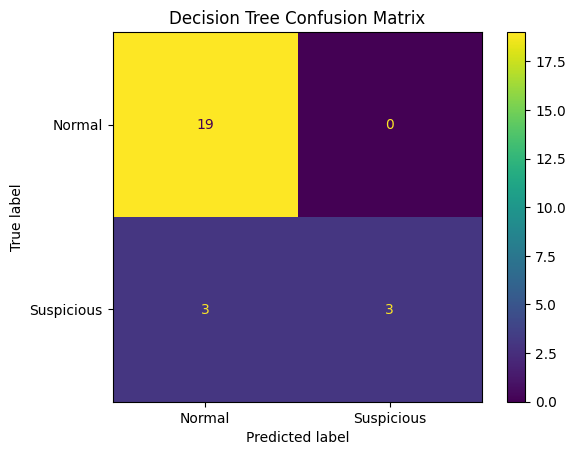

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['Normal', 'Suspicious']
)

plt.title('Decision Tree Confusion Matrix')
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
cluster_summary = df.groupby('cluster')[features].mean().round(2)

label_summary = pd.crosstab(
    df['cluster'],
    df['label']
)

print("Cluster Mean Summary:")
display(cluster_summary)

print("Cluster vs Label:")
display(label_summary)

Cluster Mean Summary:


,failed_logins,login_hour,new_device,download_mb
cluster,,,,
0,2.00,12.81,1.0,192.69
1,2.16,11.63,0.0,236.15


Cluster vs Label:


label,Normal,Suspicious
cluster,,
0,24,13
1,51,12


In [ ]:
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values(
    'importance',
    ascending=False
)

display(importance)

,feature,importance
1,login_hour,0.413391
0,failed_logins,0.392826
3,download_mb,0.193783
2,new_device,0.000000


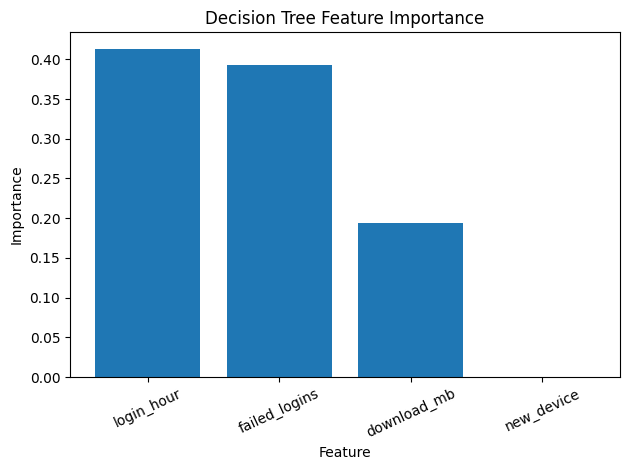

In [ ]:
plt.bar(
    importance['feature'],
    importance['importance']
)

plt.title('Decision Tree Feature Importance')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
new_records = pd.DataFrame([
    {
        'failed_logins': 0,
        'login_hour': 10,
        'new_device': 0,
        'download_mb': 45
    },
    {
        'failed_logins': 8,
        'login_hour': 2,
        'new_device': 1,
        'download_mb': 180
    },
    {
        'failed_logins': 2,
        'login_hour': 23,
        'new_device': 1,
        'download_mb': 900
    }
])

new_records['prediction'] = model.predict(new_records)

display(new_records)

,failed_logins,login_hour,new_device,download_mb,prediction
0,0,10,0,45,Normal
1,8,2,1,180,Suspicious
2,2,23,1,900,Suspicious


In [ ]:
df.to_csv(
    'Lab2_Login_ML_Result.csv',
    index=False
)

print('Saved: Lab2_Login_ML_Result.csv')

Saved: Lab2_Login_ML_Result.csv
